In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Found 983 images belonging to 6 classes.
Found 250 images belonging to 6 classes.
219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


31/31 ━━━━━━━━━━━━━━━━━━━━ 921s 24s/step - accuracy: 0.5211 - loss: 1.3360 - val_accuracy: 0.7840 - val_loss: 0.8157
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 32s 865ms/step - accuracy: 0.8433 - loss: 0.5732 - val_accuracy: 0.8040 - val_loss: 0.5697
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 41s 876ms/step - accuracy: 0.8268 - loss: 0.4701 - val_accuracy: 0.8480 - val_loss: 0.4234
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 41s 877ms/step - accuracy: 0.8860 - loss: 0.3357 - val_accuracy: 0.8760 - val_loss: 0.3824
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 42s 898ms/step - accuracy: 0.8886 - loss: 0.2925 - val_accuracy: 0.8920 - val_loss: 0.3375
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 34s 884ms/step - accuracy: 0.9062 - loss: 0.2664 - val_accuracy: 0.9080 - val_loss: 0.3063
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 39s 855ms/step - accuracy: 0.9023 - loss: 0.2493 - val_accuracy: 0.8680 - val_loss: 0.3966
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 34s 902ms/step - accuracy: 0.9231 - loss: 0.2494 - val_accuracy:

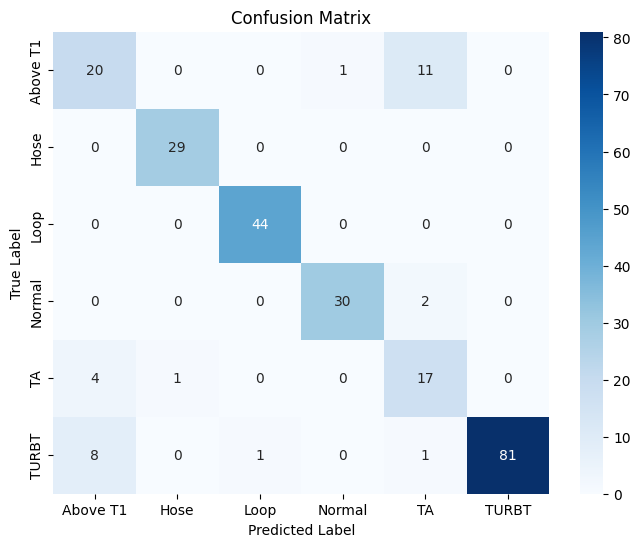

Classification Report
              precision    recall  f1-score   support

    Above T1       0.62      0.62      0.62        32
        Hose       0.97      1.00      0.98        29
        Loop       0.98      1.00      0.99        44
      Normal       0.97      0.94      0.95        32
          TA       0.55      0.77      0.64        22
       TURBT       1.00      0.89      0.94        91

    accuracy                           0.88       250
   macro avg       0.85      0.87      0.86       250
weighted avg       0.90      0.88      0.89       250



In [2]:
# Importing required libraries
import tensorflow as tf
from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define paths to your dataset
train_dir = '/content/drive/MyDrive/BLC/WLI_split/train'
test_dir = '/content/drive/MyDrive/BLC/WLI_split/test'

# Define the image size and batch size
img_size = (299, 299)  # InceptionResNetV2 requires 299x299 images
batch_size = 32

# Data augmentation for training data
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=20,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

# Rescaling for test data
test_datagen = ImageDataGenerator(rescale=1./255)

# Load the training and testing datasets
train_generator = train_datagen.flow_from_directory(train_dir,
                                                    target_size=img_size,
                                                    batch_size=batch_size,
                                                    class_mode='categorical')

test_generator = test_datagen.flow_from_directory(test_dir,
                                                  target_size=img_size,
                                                  batch_size=batch_size,
                                                  class_mode='categorical',
                                                  shuffle=False)

# Load the InceptionResNetV2 model with ImageNet weights, exclude top layers
base_model = InceptionResNetV2(weights='imagenet', include_top=False, input_shape=(299, 299, 3))

# Freeze the convolutional base to prevent updating pre-trained weights
for layer in base_model.layers:
    layer.trainable = False

# Adding custom layers for your 6 classes
x = base_model.output
x = GlobalAveragePooling2D()(x)  # Use Global Average Pooling instead of Flatten
x = Dense(1024, activation='relu')(x)  # Fully connected layer
x = Dense(512, activation='relu')(x)  # Another dense layer
predictions = Dense(6, activation='softmax')(x)  # 6 classes

# Combine base model and custom layers
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(train_generator,
                    epochs=100,
                    validation_data=test_generator)

# Evaluate the model on test data
test_loss, test_acc = model.evaluate(test_generator)
print(f'Test accuracy: {test_acc:.4f}')

# Predict on test data
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)

# Confusion Matrix and Classification Report
class_labels = list(test_generator.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(test_generator.classes, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Classification report
print('Classification Report')
report = classification_report(test_generator.classes, y_pred, target_names=class_labels)
print(report)
